# 06 — Fairness audit by sex (LightGBM v1 and v2)

Development set only (out-of-fold predictions); the test set is not used.

**Scripts run, this notebook explains.** Every number here is produced by
`src/fairness.py` and saved in `reports/`; this notebook only reads those files
and comments on them (no training here).

| Section | Model | Command (from the project root) | Output |
|---|---|---|---|
| 2. Audit v1 | LightGBM tuned v1 + Platt | `python3 -m src.fairness audit` with `BEST_PARAMS_VERSION = "v1"` (2026-10-20) | `fairness_dev.json` (rows `version = "v1"`), `figures/fairness_by_sex_dev.png` |
| 3. Audit v2 | LightGBM tuned v2 + Platt (the recalibrated candidate model) | `python3 -m src.fairness audit` with `BEST_PARAMS_VERSION = "v2"` (2026-10-21) | `fairness_dev.json` (rows `version = "v2"`), `fairness_details_dev_v2.json`, `figures/fairness_by_sex_dev_v2.png` |

`fairness_dev.json` keeps both versions: a new run only replaces the rows of
its own version.

Course sessions used: **S9** fairness definitions, the impossibility result,
post-processing mitigation; **S6** decision thresholds; **S7** calibration by
group; **S8** uncertainty of a gap (bootstrap).

In [1]:
import json
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
REPORTS = ROOT / "reports"
summary = pd.read_json(REPORTS / "fairness_dev.json")
PERF = ["rule", "accuracy", "balanced_accuracy", "f1", "precision", "recall"]
GAPS = ["rule", "dp_diff", "tpr_diff", "fpr_diff", "equalized_odds_gap", "ppv_diff",
        "four_fifths_ratio"]

## 1. What is measured

**The decision.** The model gives each person a probability of earning more
than $50K; a client flags everyone above a **threshold** (e.g. for an audit).
Fairness is measured on these flags, separately for women and men:

| Rate | Meaning | Here |
|---|---|---|
| **Selection rate** | share of the group that is flagged | who gets the decision |
| **TPR** (true positive rate, recall) | share of the real high earners who are flagged | high earners the model *finds* |
| **FPR** (false positive rate) | share of the people under $50K who are wrongly flagged | *wrong flags* |
| **PPV** (precision) | share of the flagged people who really are high earners | what a flag *means* |

**Fairness definitions, fixed before looking at any result** (`src/fairness.py`):
- **primary: equalized odds** = the same TPR *and* the same FPR for women and
  men (the model makes the same mistakes at the same rates); the
  *equalized-odds gap* is the larger of the two gaps;
- **legal screen: the four-fifths rule** = women's selection rate divided by
  men's should be at least 0.8;
- also reported: **demographic parity** (same selection rate), **equal
  opportunity** (same TPR only), **predictive parity** (same PPV).

Gaps are always **women minus men** (negative = lower for women).

**Decision rules compared** (all on the same out-of-fold probabilities):
- *before the mitigation:* one threshold for everyone, chosen without looking
  at sex: the **best-F1** threshold (the neutral operating point) and the
  **best balanced-accuracy** threshold (the same objective as the mitigation,
  so the fair "before" for it);
- *after:* Fairlearn's `ThresholdOptimizer` (S9 post-processing) chooses **one
  threshold per sex** to satisfy a constraint: equalized odds (the mitigation),
  and, as a sensitivity analysis, equal opportunity and demographic parity. It
  is fitted on the out-of-fold probabilities and scored by a second 5-fold CV,
  so it is never scored on the people it was fitted on.

Development set: 12,917 women (11% high earners) and 26,115 men (30%).

## 2. Audit v1: LightGBM tuned v1 + Platt (2026-10-20)

The first audit, on the v1 parameters (with `scale_pos_weight` 1.32, whose raw
probabilities were over-confident; Platt scaling corrected them, F23).

In [2]:
v1 = summary[summary["version"] == "v1"]
print("v1: performance of each decision rule (all people)")
display(v1[PERF].round(3))
print("v1: fairness gaps (women minus men; four-fifths ratio = women / men)")
display(v1[GAPS].round(3))

v1: performance of each decision rule (all people)


,rule,accuracy,balanced_accuracy,f1,precision,recall
0,single threshold (best F1),0.817,0.806,0.672,0.589,0.783
1,single threshold (best balanced accuracy),0.787,0.811,0.658,0.534,0.859
2,equalized odds (ThresholdOptimizer),0.760,0.782,0.622,0.499,0.825
3,equal opportunity (ThresholdOptimizer),0.787,0.804,0.653,0.535,0.837
4,demographic parity (ThresholdOptimizer),0.765,0.770,0.613,0.505,0.780


v1: fairness gaps (women minus men; four-fifths ratio = women / men)


,rule,dp_diff,tpr_diff,fpr_diff,equalized_odds_gap,ppv_diff,four_fifths_ratio
0,single threshold (best F1),-0.299,-0.191,-0.189,0.191,-0.015,0.282
1,single threshold (best balanced accuracy),-0.327,-0.143,-0.228,0.228,-0.057,0.337
2,equalized odds (ThresholdOptimizer),-0.111,0.006,-0.003,0.006,-0.296,0.743
3,equal opportunity (ThresholdOptimizer),-0.213,-0.001,-0.116,0.116,-0.177,0.521
4,demographic parity (ThresholdOptimizer),0.001,0.179,0.099,0.179,-0.343,1.002


Women vs men at the best-F1 threshold (0.321), v1. The per-group rates of the
v1 run were printed by the script, not saved to a file; they are copied from
section 3d of `docs/findings_log.md`:

| Group | n | Base rate | Selection rate | TPR | FPR | PPV |
|---|---|---|---|---|---|---|
| Women | 12,917 | 0.109 | 0.118 | 0.621 | 0.056 | 0.577 |
| Men | 26,115 | 0.304 | 0.417 | 0.812 | 0.245 | 0.591 |

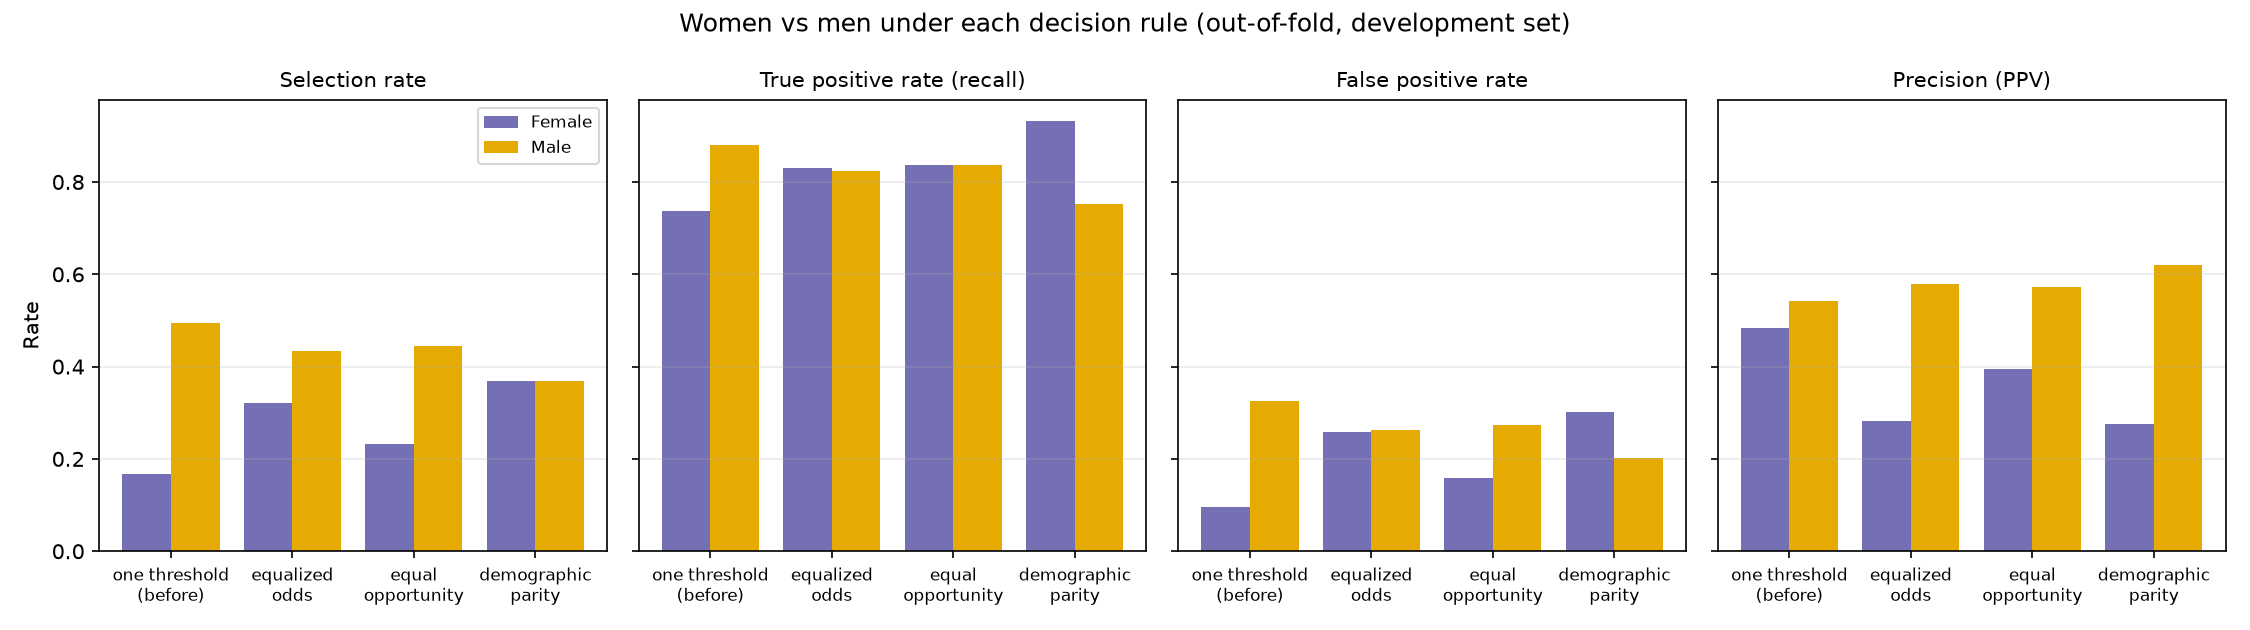

In [3]:
display(Image(str(REPORTS / "figures" / "fairness_by_sex_dev.png")))

### How to read `fairness_by_sex_dev.png`

Four panels, one per rate; in each panel, four pairs of bars (purple = women,
yellow = men), one pair per decision rule: **one threshold (before)** = the
best balanced-accuracy threshold for everyone, then the three per-sex
threshold rules of `ThresholdOptimizer`. Equal bars in a panel = parity on that
rate.

- **Selection rate (who is flagged).** Before: about 17% of women vs 49% of
  men are flagged (four-fifths ratio 0.34, far below 0.8). Part of this is the
  base rate (11% vs 30% are high earners). Only demographic parity makes the
  bars equal, by construction; equalized odds narrows the gap (ratio 0.74).
- **TPR (high earners found).** Before: the model finds about 74% of the
  high-earning women vs 88% of the men. Equalized odds and equal opportunity
  make the bars equal (about 0.83). Demographic parity overshoots: it finds
  more women than men (0.93 vs 0.75), because it must flag as many women as
  men although fewer women are high earners.
- **FPR (wrong flags).** Before: about 10% of women under $50K are wrongly
  flagged vs 33% of men: the errors fall the other way (men are flagged too
  easily). Equalized odds makes the bars equal (about 0.26); equal opportunity
  does not (it only equalises TPR); demographic parity reverses the gap.
- **Precision (what a flag means).** Before, a flag means nearly the same for
  both (0.48 vs 0.54 at this threshold; 0.58 vs 0.59 at the best-F1 threshold).
  **Every mitigation opens this gap:** with equalized odds, only 28% of flagged
  women are high earners vs 58% of men. To find as many high-earning women as
  men, the threshold for women must be lowered, which flags many women who are
  not high earners.

**Reading of v1** (F25-F27).
- **Before:** unequal error rates (TPR gap −0.19, FPR gap −0.19 at the best-F1
  threshold) and unequal selection (four-fifths ratio 0.28), but an equal
  meaning of a flag (PPV gap −0.015).
- **Equalized odds closes the error-rate gaps** (equalized-odds gap 0.228 →
  0.006 vs the balanced-accuracy threshold) at a modest cost (balanced accuracy
  0.811 → 0.782) and **widens the precision gap** (−0.057 → −0.296).
- **The definitions cannot all be satisfied** (S9 impossibility): with
  different base rates, equal error rates and equal precision exclude each
  other; demographic parity equalises selection but opens the TPR gap (+0.18).

## 3. Audit v2: LightGBM tuned v2 + Platt, the recalibrated candidate model (2026-10-21)

Same script, same definitions, same decision rules, on the v2 parameters (no
class weight). LightGBM v2 is already calibrated, so Platt scaling leaves its
probabilities practically unchanged (notebook 05, section 1: ECE 0.0058 raw vs
0.0057 Platt). This run also saves the per-group rates
(`fairness_details_dev_v2.json`).

In [4]:
details = json.loads((REPORTS / "fairness_details_dev_v2.json").read_text())
print("Thresholds (one for everyone):", {k: round(v, 3) for k, v in details["thresholds"].items()})
for rule in ["single threshold (best F1)", "single threshold (best balanced accuracy)",
             "equalized odds (ThresholdOptimizer)"]:
    print(f"\nv2, women vs men: {rule}")
    display(pd.DataFrame(details["by_sex"][rule]).set_index("group").round(3))

v2 = summary[summary["version"] == "v2"]
print("v2: performance of each decision rule (all people)")
display(v2[PERF].round(3))
print("v2: fairness gaps (women minus men; four-fifths ratio = women / men)")
display(v2[GAPS].round(3))
print("v2: 95% bootstrap intervals of the gaps, best-F1 threshold (500 resamples of people)")
display(pd.DataFrame(details["bootstrap_95_best_f1"], index=["2.5%", "97.5%"]).round(3))

Thresholds (one for everyone): {'best_f1': 0.342, 'best_balanced_accuracy': 0.208}

v2, women vs men: single threshold (best F1)


,n,selection_rate,tpr,fpr,ppv,base_rate
group,,,,,,
Female,12917.0,0.107,0.589,0.048,0.600,0.109
Male,26115.0,0.391,0.783,0.220,0.608,0.304



v2, women vs men: single threshold (best balanced accuracy)


,n,selection_rate,tpr,fpr,ppv,base_rate
group,,,,,,
Female,12917.0,0.172,0.749,0.102,0.475,0.109
Male,26115.0,0.506,0.891,0.338,0.535,0.304



v2, women vs men: equalized odds (ThresholdOptimizer)


...

,rule,accuracy,balanced_accuracy,f1,precision,recall
5,single threshold (best F1),0.824,0.800,0.672,0.607,0.753
6,single threshold (best balanced accuracy),0.781,0.812,0.656,0.526,0.870
7,equalized odds (ThresholdOptimizer),0.758,0.783,0.622,0.497,0.829
8,equal opportunity (ThresholdOptimizer),0.789,0.803,0.653,0.538,0.832
9,demographic parity (ThresholdOptimizer),0.759,0.772,0.612,0.497,0.797


v2: fairness gaps (women minus men; four-fifths ratio = women / men)


,rule,dp_diff,tpr_diff,fpr_diff,equalized_odds_gap,ppv_diff,four_fifths_ratio
5,single threshold (best F1),-0.284,-0.194,-0.172,0.194,-0.007,0.274
6,single threshold (best balanced accuracy),-0.333,-0.142,-0.236,0.236,-0.060,0.341
7,equalized odds (ThresholdOptimizer),-0.110,0.003,-0.001,0.003,-0.298,0.747
8,equal opportunity (ThresholdOptimizer),-0.212,-0.003,-0.115,0.115,-0.176,0.518
9,demographic parity (ThresholdOptimizer),-0.000,0.167,0.101,0.167,-0.343,0.999


v2: 95% bootstrap intervals of the gaps, best-F1 threshold (500 resamples of people)


,tpr_diff,fpr_diff,dp_diff,four_fifths_ratio
2.5%,-0.222,-0.180,-0.292,0.259
97.5%,-0.167,-0.165,-0.276,0.288


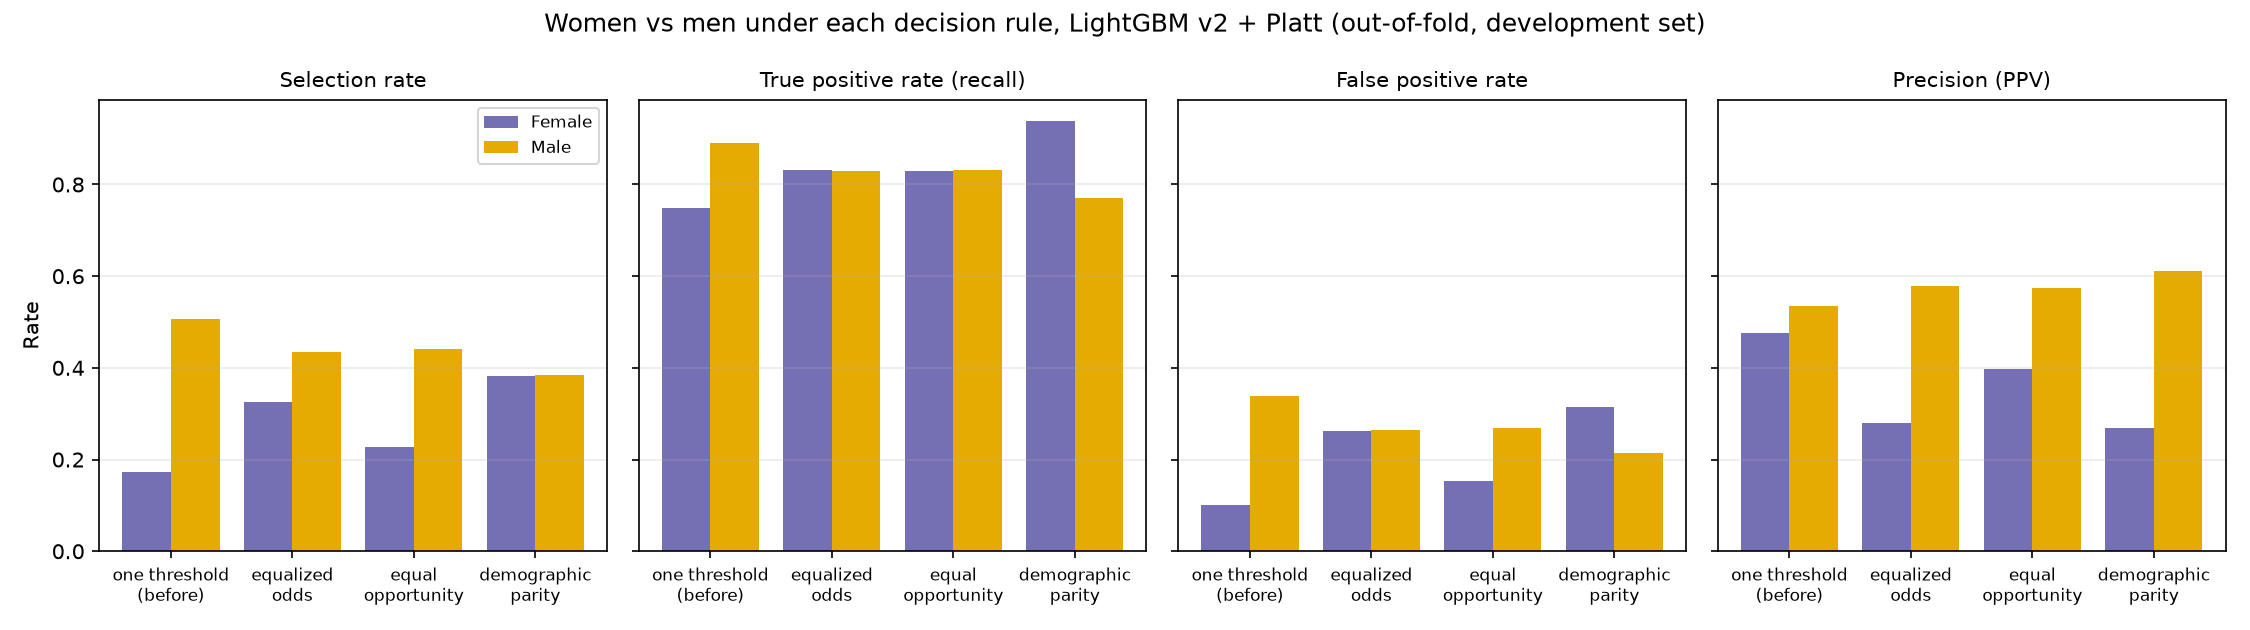

In [5]:
display(Image(str(REPORTS / "figures" / "fairness_by_sex_dev_v2.png")))

**Reading of v2** (same layout as the v1 figure, section 2).
- **Before the mitigation, the same pattern as v1.** At the best-F1 threshold
  (0.342) the model finds 58.9% of the high-earning women vs 78.3% of the men
  (TPR gap −0.194) and wrongly flags 4.8% of the women under $50K vs 22.0% of
  the men (FPR gap −0.172): equalized-odds gap 0.194. It flags 10.7% of women vs
  39.1% of men: four-fifths ratio **0.27**, far below 0.8. None of the 95%
  bootstrap intervals comes near 0 (TPR gap [−0.222, −0.167]): these gaps are
  not noise.
- **A flag still means the same for women and men:** PPV 0.600 vs 0.608 (gap
  −0.007, v1 −0.015). This is predictive parity, and it follows from the good
  calibration by sex (notebook 05: women 0.112 predicted vs 0.109 observed, men
  0.302 vs 0.304).
- **Equalized odds closes the error-rate gaps:** TPR gap +0.003, FPR gap
  −0.001 (equalized-odds gap 0.236 → 0.003 vs the balanced-accuracy threshold).
  **Cost:** balanced accuracy 0.812 → 0.783, accuracy 0.781 → 0.758, precision
  0.526 → 0.497. The four-fifths ratio rises from 0.34 to 0.75, still just under
  0.8.
- **How it gets there:** it moves both thresholds. Women are flagged more
  (selection 17.2% → 32.5%; TPR 0.749 → 0.832, but FPR 0.102 → 0.263) and men
  less (selection 50.6% → 43.6%; FPR 0.338 → 0.264, TPR 0.891 → 0.828). Both
  groups end at TPR ≈ 0.83 and FPR ≈ 0.26.
- **And it opens the precision gap:** PPV gap −0.060 → −0.298 (0.28 for women
  vs 0.58 for men under equalized odds, figure, right panel).
- **Sensitivity:** equal opportunity closes only the TPR gap (FPR gap −0.115
  remains); demographic parity reaches a ratio of 0.999 but opens a TPR gap of
  +0.167 and the largest precision gap (−0.343). The S9 impossibility holds
  again: with base rates of 0.109 and 0.304, no rule can equalise selection,
  error rates and precision at the same time.

In [6]:
print("v2, by race at the best-F1 threshold (groups under 500 people are unstable)")
display(pd.DataFrame(details["by_race_best_f1"]).set_index("group").round(3))

v2, by race at the best-F1 threshold (groups under 500 people are unstable)


,n,selection_rate,tpr,fpr,ppv,base_rate,small_group
group,,,,,,,
Amer-Indian-Eskimo,383.0,0.172,0.619,0.117,0.394,0.110,True
Asian-Pac-Islander,1206.0,0.350,0.773,0.199,0.581,0.263,False
Black,3784.0,0.147,0.665,0.074,0.559,0.124,False
Other,326.0,0.147,0.675,0.073,0.562,0.123,True
White,33333.0,0.315,0.759,0.164,0.612,0.254,False


**By race (v2, best-F1 threshold).** Black people are flagged less (14.7% vs
31.5% for White people, base rates 12.4% vs 25.4%), with a lower TPR (0.665 vs
0.759) and a lower FPR (0.074 vs 0.164): the same pattern as for women. The
American-Indian-Eskimo (383 people) and Other (326) groups are too small for
stable rates (F28). The mitigation in this project targets sex only.

## 4. v1 vs v2: did the tuning change the bias?

In [7]:
cols = ["equalized_odds_gap", "tpr_diff", "fpr_diff", "ppv_diff", "four_fifths_ratio",
        "balanced_accuracy", "f1"]
both = summary.pivot(index="rule", columns="version", values=cols)
both = both.reindex(summary["rule"].drop_duplicates())
display(both.round(3))

equalized_odds_gap        tpr_diff  \
version                                                   v1     v2       v1   
rule                                                                           
single threshold (best F1)                             0.191  0.194   -0.191   
single threshold (best balanced accuracy)              0.228  0.236   -0.143   
equalized odds (ThresholdOptimizer)                    0.006  0.003    0.006   
equal opportunity (ThresholdOptimizer)                 0.116  0.115   -0.001   
demographic parity (ThresholdOptimizer)                0.179  0.167    0.179   

                                                 fpr_diff        ppv_diff  \
version                                       v2       v1     v2       v1   
rule                                                                        
single threshold (best F1)                -0.194   -0.189 -0.172   -0.015   
single threshold (best balanced accuracy) -0.142   -0.228 -0.236   -0.057   
equalized odds (ThresholdOptimizer)        0.003   -0.003 -0.001   -0.296   
equal opportunity (ThresholdOptimizer)    -0.003   -0.116 -0.115   -0.177   
demographic parity (ThresholdOptimizer)    0.167    0.099  0.101   -0.343   

                                                 four_fifths_ratio         \
version                                       v2                v1     v2   
rule                                                                        
single threshold (best F1)                -0.007             0.282  0.274   
single threshold (best balanced accuracy) -0.060             0.337  0.341   
equalized odds (ThresholdOptimizer)       -0.298             0.743  0.747   
equal opportunity (ThresholdOptimizer)    -0.176             0.521  0.518   
demographic parity (ThresholdOptimizer)   -0.343             1.002  0.999   

                                          balanced_accuracy            f1  \
version                                                  v1     v2     v1   
rule                                                                        
single threshold (best F1)                            0.806  0.800  0.672   
single threshold (best balanced accuracy)             0.811  0.812  0.658   
equalized odds (ThresholdOptimizer)                   0.782  0.783  0.622   
equal opportunity (ThresholdOptimizer)                0.804  0.803  0.653   
demographic parity (ThresholdOptimizer)               0.770  0.772  0.613   

                                                  
version                                       v2  
rule                                              
single threshold (best F1)                 0.672  
single threshold (best balanced accuracy)  0.656  
equalized odds (ThresholdOptimizer)        0.622  
equal opportunity (ThresholdOptimizer)     0.653  
demographic parity (ThresholdOptimizer)    0.612

**Reading.**
- **The bias did not move.** Equalized-odds gap 0.191 (v1) vs 0.194 (v2) at the
  best-F1 threshold, four-fifths ratio 0.282 vs 0.274, PPV gap −0.015 vs
  −0.007. The mitigation results are the same within 0.005 (equalized odds:
  gap 0.006 vs 0.003, balanced accuracy 0.782 vs 0.783, PPV gap −0.296 vs
  −0.298).
- **So the bias is not a tuning or calibration artefact.** v2 changed the
  class weight, the tree size and the number of trees, and fixed the
  calibration; the gaps between women and men stayed where they were. They come
  from the data the model learns from: the inputs are proxies for sex (marital
  status, occupation, hours, F30-F31), and the base rates differ (11% vs 30%).
- **The operating point moved a little:** without the class weight, v2's
  probabilities are lower, so the best-F1 threshold rises (0.321 → 0.342) and v2
  flags slightly fewer people (precision 0.589 → 0.607, recall 0.783 → 0.753 at
  the best-F1 threshold), with the same F1 (0.672).

## 5. Findings

1. **Before any mitigation, LightGBM v2 treats women and men differently on
   errors and selection, not on the meaning of a flag.** Best-F1 threshold: TPR
   0.589 vs 0.783, FPR 0.048 vs 0.220 (equalized-odds gap 0.194), selection
   10.7% vs 39.1% (four-fifths ratio 0.27), PPV 0.600 vs 0.608. The bootstrap
   intervals exclude 0.
2. **Equalized odds (per-sex thresholds) closes the error-rate gaps** (gap
   0.003) for about 0.03 balanced accuracy, raises the four-fifths ratio to
   0.75, and **opens the precision gap** (−0.298).
3. **The fairness definitions conflict**, as the S9 impossibility result
   predicts when base rates differ: each rule fixes one rate and breaks another.
4. **v1 and v2 give the same picture:** the tuning and the calibration did not
   create or remove the bias; it comes from the proxies in the data.
5. **Caveats:** development set only, out-of-fold; per-sex thresholds use sex
   at decision time, which is a policy and legal decision, not a technical one
   (F29). The before / after must be confirmed once on the test set.

Details: findings F25-F29 (v1) and F42 (v2) in `docs/findings_log.md`.